In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
# ============================================================
# 1. CARGAR EL DATASET
# ============================================================
digits = load_digits()

print("Total de imágenes:", len(digits.images))
print("Dimensión de imágenes:", digits.images.shape)
print("Dimensión de etiquetas:", digits.target.shape)
print("Clases disponibles:", digits.target_names)

Total de imágenes: 1797
Dimensión de imágenes: (1797, 8, 8)
Dimensión de etiquetas: (1797,)
Clases disponibles: [0 1 2 3 4 5 6 7 8 9]


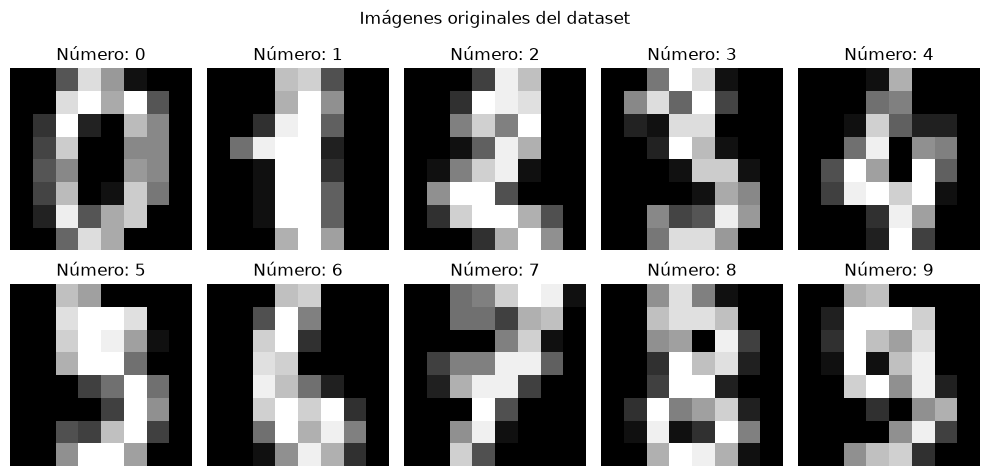

In [3]:
# ============================================================
# 2. VISUALIZAR LAS PRIMERAS 10 IMÁGENES
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, image, label in zip(
    axes.flat,
    digits.images[:10],
    digits.target[:10]
):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Número: {label}")
    ax.axis("off")

plt.suptitle("Imágenes originales del dataset")
plt.tight_layout()
plt.show()

In [4]:
# ============================================================
# 3. CONVERTIR IMÁGENES A VECTORES
# ============================================================
n_samples = len(digits.images)

# Cada imagen (8, 8) pasa a un vector de 64 valores
X = digits.images.reshape((n_samples, -1))
print("X first image before reshaping:", digits.images[0])

# Respuestas correctas: números del 0 al 9
y = digits.target
print("y first label before reshaping:", digits.target[0])

print("X shape:", X.shape)  # (1797, 64)
print("y shape:", y.shape)  # (1797,)

X first image before reshaping: [[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
y first label before reshaping: 0
X shape: (1797, 64)
y shape: (1797,)


In [5]:
# ============================================================
# 4. DIVIDIR TRAINING Y TEST
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=True,
    stratify=y,
    random_state=42
)

print("Training:", X_train.shape)  # (1437, 64)
print("Test:", X_test.shape)       # (360, 64)

Training: (1437, 64)
Test: (360, 64)


In [6]:
# ============================================================
# 5. CREAR EL CLASIFICADOR SVC
# ============================================================
svc = SVC(
    kernel="rbf",
    gamma=0.001,
    C=100.0
)

In [7]:
# ============================================================
# 6. ENTRENAR EL MODELO
# ============================================================
svc.fit(X_train, y_train)

print("Entrenamiento finalizado")
print("Vectores de soporte:", len(svc.support_))

Entrenamiento finalizado
Vectores de soporte: 701


In [8]:
# ============================================================
# 7. PREDECIR LOS DÍGITOS DEL TEST
# ============================================================
y_pred = svc.predict(X_test)

print("Primeras predicciones:", y_pred[:10])
print("Primeras respuestas:", y_test[:10])

Primeras predicciones: [5 2 8 1 7 2 6 2 6 5]
Primeras respuestas: [5 2 8 1 7 2 6 2 6 5]


In [9]:
# ============================================================
# 8. EVALUAR LA PRECISIÓN DEL MODELO
# ============================================================
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.2%}")
print("Errores:", np.sum(y_pred != y_test))

print("\nClassification report:")
print(classification_report(y_test, y_pred))


Test accuracy: 99.17%
Errores: 3

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.97      0.97      0.97        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



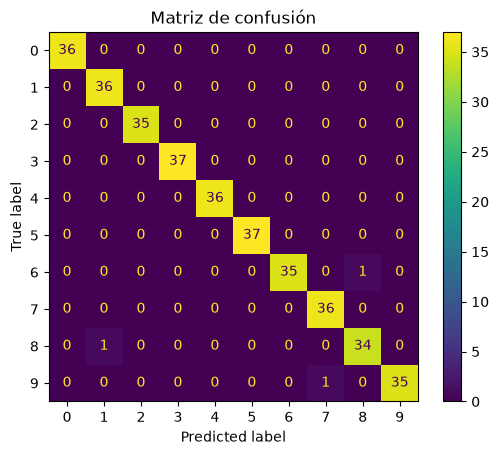

In [10]:
# ============================================================
# 9. MOSTRAR LA MATRIZ DE CONFUSIÓN
# ============================================================
disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=digits.target_names
)

disp.ax_.set_title("Matriz de confusión")
plt.show()

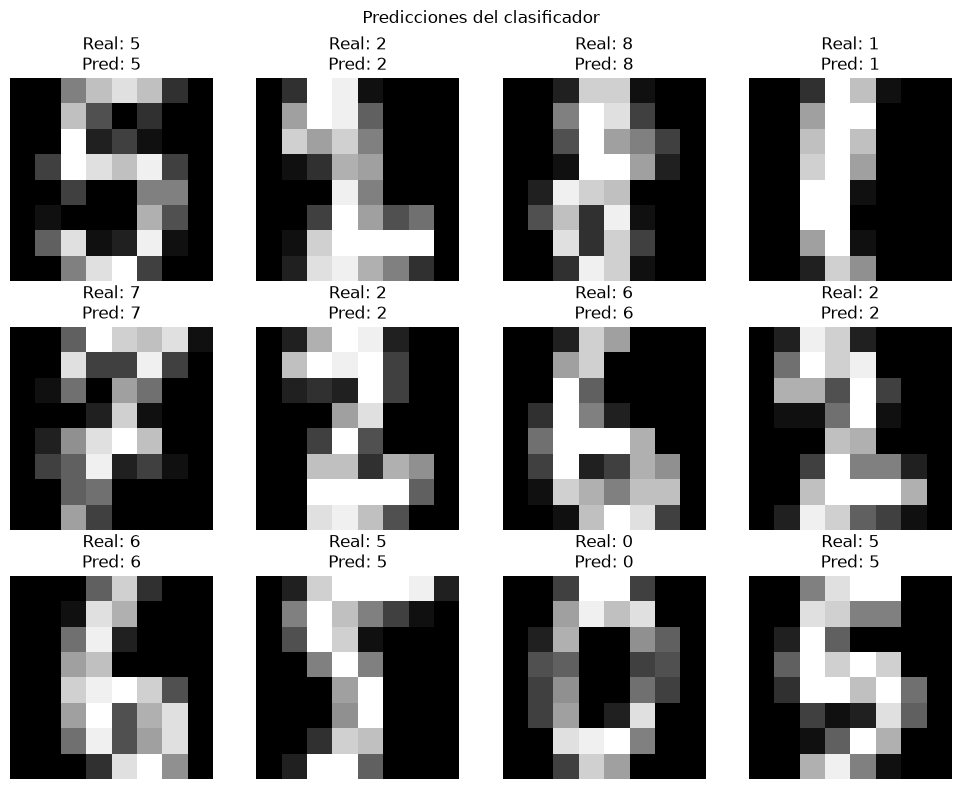

In [11]:
# ============================================================
# 10. MOSTRAR 12 PREDICCIONES
# ============================================================
fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    image = X_test[i].reshape(8, 8)

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"Real: {y_test[i]}\nPred: {y_pred[i]}"
    )
    ax.axis("off")

plt.suptitle("Predicciones del clasificador")
plt.tight_layout()
plt.show()

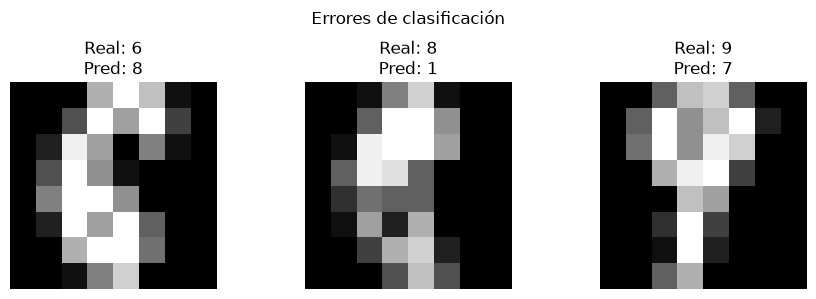

In [12]:
# ============================================================
# 11. INSPECCIONAR LOS ERRORES
# ============================================================
error_indices = np.where(y_pred != y_test)[0]

if len(error_indices) > 0:
    selected = error_indices[:6]

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(3 * len(selected), 3)
    )

    for ax, idx in zip(np.atleast_1d(axes), selected):
        ax.imshow(X_test[idx].reshape(8, 8), cmap="gray")
        ax.set_title(
            f"Real: {y_test[idx]}\nPred: {y_pred[idx]}"
        )
        ax.axis("off")

    plt.suptitle("Errores de clasificación")
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron errores en este test")

Predicción: 9
Valor real: 9
Precision: 1.0


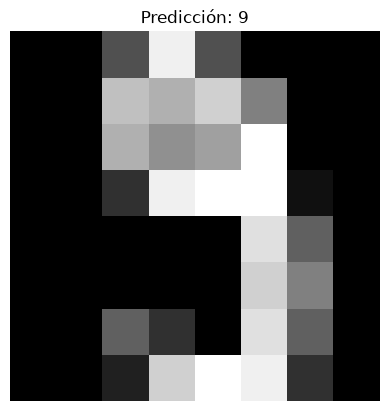

In [17]:
# ============================================================
# 12. PREDECIR UNA SOLA IMAGEN
# ============================================================
index = 257
sample = X_test[index].reshape(1, -1)

prediction = svc.predict(sample)[0]

print("Predicción:", prediction)
print("Valor real:", y_test[index])
print("Precision:", accuracy_score([y_test[index]], [prediction]))

plt.imshow(sample.reshape(8, 8), cmap="gray")
plt.title(f"Predicción: {prediction}")
plt.axis("off")
plt.show()